# How tuning sharpens a code model's algorithm choice
### Demo of claim B2: cross-model activation patching at the algorithm fork (Qwen3-8B vs Qwen3-8B-Base)

Ask an instruction-tuned code model to return the cost of a minimum spanning tree, or to count connected components,
and it almost always writes the same algorithm: Kruskal, or union-find. This artifact (iteration 9, claims B1-B3) tests
the run's question *"does an LLM just give the mean answer?"* at the **single token where the model commits to an
algorithm**, the **fork**. It compares a tuned model with its own base model on identical token ids.

* **Fork margin** `m = log P(D) - log P(A)` at the fork. D is the instruct model's default class of next tokens
  (MST: `' Kr'`(uskal), `' Union'`, ...; connected components: `' find'`) and A is the alternative class
  (MST: `' Prim'`, ...; CC: `' dfs'`, `' bfs'`). The prompt and the instruct model's own code opening are
  teacher-forced, e.g. `def solve(n, roads): import heapq ... # Build adjacency list ... #` → next token `' Kr'` or
  `' Prim'`.
* The instruct model is much more decided than its base. The gap `m_I - m_B` is about 2.1 nats on the MST unit (**B3**)
  and 4.5 nats on the connected-components unit (**T10**).
* **CMAP** (cross-model activation patching): in the instruct forward pass, at the fork position only, the output of a
  set X of components (MLPs and/or attention heads) is replaced by the base model's output on the same ids.
  **share(X) = Σ_p (m_I − m_X) / Σ_p (m_I − m_B)** is the fraction of the instruct-minus-base gap that X carries. A
  share of 1 means patching X turns the instruct fork distribution into the base one.
* Tested sets: **FSTACK** (10 fork-stack nodes validated in iteration 8: 5 late MLPs and 5 heads), every single
  component (36 MLPs + 1152 heads), **50 random sets** matched to FSTACK by layer band and write norm (the null), the
  task-specification nodes (**SPEC**), residual-stream swaps (**RS**) at every depth, a reverse patch (**REV**) and a
  weight swap (**W**).

**What this notebook runs.** The GPU stages of `method.py` need a 24 GB GPU and the 16 GB Qwen weights: the
Qwen3-8B / Qwen3-8B-Base captures and 1429 patched fork margins per prompt. The demo file `mini_demo_data.json` holds
their real per-prompt output: 2 units × 20 prompts × 1429 patching arms, the 55 REV arms, and the block-30 fork
activations of four states. On that data the notebook runs the **original CPU code**:

* the matched-random-set construction (`src/cmap9.py`);
* the committed B2 decision rules (`src/analysis9.py`);
* figures F3-F5 and an F8-style activation-geometry plot (`src/figures9.py`);
* the independent standard-library re-derivation with placebos (`src/rederive9.py`).

Nothing is simulated or mocked.

| claim | models | headline of the original run | in this notebook |
|---|---|---|---|
| B1 behavioural | Gemma-3-4b pt/it, Llama-3.1-8B base/instruct | instruct sharper at the fork (gains 1.7-3.1 nats) while ordinary positions barely change; but JS at forks ≈ JS at base-entropy-matched positions → PARTIAL | quoted only |
| **B2 mechanistic** | **Qwen3-8B vs Qwen3-8B-Base** | MST: FSTACK closes 1.00 of the gap, but matched random late sets close a median 0.81 (p = 0.45). CC: FSTACK 0.45 vs random −0.22 (p = 0.020). The tuned unembedding alone carries 43 % / 85 % of the gap → PARTIAL, "distributed" | **recomputed from the per-prompt rows** |
| B2 generation | Qwen3-8B, N = 30 CRN slots per arm | a one-token FSTACK patch flips 19/30 MST programs to (correct) Prim, but a matched random set also gives 19/30; on CC only replacing the whole fork distribution moves the choice | quoted only |
| B3 | Qwen3-8B | iteration-8 MeanCache bug confirmed; held-out layer-0 condition-MLP effect 3.86 nats (ablate) / 3.85 (steer) | quoted only |

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT on Colab, always install (the original scripts log with loguru)
_pip('loguru==0.7.3')

# numpy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py
import argparse
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/cfg9.py, src/stats9.py, src/analysis9.py, src/cmap9.py (CPU part), src/rederive9.py
import base64          # notebook only: decodes the bf16 fork states stored in mini_demo_data.json
import hashlib
import itertools
import json
import math
import os
import random
import statistics
from datetime import datetime, timezone
from types import SimpleNamespace   # notebook only: stands in for `import stats9 as S`
from typing import Any, Iterable, Sequence

import numpy as np

# --- src/figures9.py (it also imported torch, used only for torch.load of cache/*.pt; the demo data carries those
# vectors, so torch is not needed. matplotlib.use("Agg") is dropped so figures display inline.)
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_jSassd-YWLVC/round-9/experiment-50/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
M = data["metadata"]
print(M["title"])
print(f"{M['n_examples']} examples (unit x prompt); source: {M['source']}")
for u, U in M["units"].items():
    ex_u = [e for e in data["examples"] if e["unit"] == u]
    print(f"  {u}: {U['name']}: {len(ex_u)} prompts x {len(ex_u[0]['arms'])} patching arms "
          f"(+ {len(ex_u[0]['rev_arms'])} REV arms); D = {U['D_class']} {U['D_tokens'][:3]}..., "
          f"A = {U['A_class']} {U['A_tokens'][:3]}...")
e0 = data["examples"][0]
print("\nexample", e0["unit"], e0["pid"], "| the prompt + opening ends with:\n" + e0["input"][-260:])
print(f"-> instruct argmax {e0['output']!r}, base argmax {e0['predict_base_model']!r}; "
      f"m_I = {e0['m_I']:.3f}, m_B = {e0['m_B']:.3f} nats")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
How tuning sharpens a code model's algorithm choice: B2 cross-model activation patching rows
40 examples (unit x prompt); source: iteration-9 artifact art_cDba8_DycUJd (experiment 50), dataset b2_tf
  B3: minimum spanning tree weight: 20 prompts x 1429 patching arms (+ 55 REV arms); D = kruskal [' Kr', ' Union', ' Check']..., A = prim_heap [' Prim', ' Pr', ' Use']...
  T10: connected components: 20 prompts x 1429 patching arms (+ 55 REV arms); D = union_find [' find']..., A = dfs|bfs [' dfs', ' bfs']...

example B3 W1|guy | the prompt + opening ends with:
.<|im_end|>
<|im_start|>assistant
<think>

</think>

```python
def solve(n, roads):
    import heapq

    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v, w in roads:
        graph[u].append((v, w))
        graph[v].append((u, w))

    #
-> instruct argmax ' Kr', base argmax ' Prim'; m_I = 1.298, m_B = -0.806 nats


## Configuration

Every tunable parameter is set here. The values below are the original run's values. With them the whole notebook
runs in well under a minute on a CPU, because all the heavy computation (the patched forward passes) happened on the
GPU and is stored in the demo data. Smaller values give the same pipeline on a subset; the minimum that still produces
every output is noted in the comments.

In [5]:
N_PROMPTS_PER_UNIT = 20     # prompts per unit taken from the data (original: 20 = all; minimum 2)
N_BOOT = 10000              # bootstrap resamples per CI, cfg9.N_BOOT (original: 10000; minimum 10)
N_RAND = 50                 # matched random component sets per null R / R-pure / R-scaled, cfg9.N_RAND (original: 50; minimum 2)
N_RAND_SPEC = 20            # matched random SPEC sets, cfg9.N_RAND_SPEC (original: 20; minimum 2)
N_PLACEBO_DRAWS = 200       # placebo draws in the stdlib re-derivation, rederive9.b2 (original: 200; minimum 2)

## 1. The pipeline (`method.py`)

`method.py` is a stage runner. Each stage runs one script from `src/` in its own process
(`subprocess.run([PY, *cmd], cwd=SRC)`), so only one model is on the GPU at a time. Run in the original order, the
stages produce the commitment chain, then the GPU captures and patched passes, then the CPU analysis. Below is its
`STAGES` table, copied verbatim. The cell marks the CPU stages that this notebook replays on the stored rows. All
other stages need the models and a GPU (about 1 GPU-hour on one 24 GB L4 for `--stages all`).

In [6]:
STAGES: dict[str, list[list[str]]] = {
    "preflight": [["s0_preflight.py"]],
    "units": [["units9.py"]],
    "tests": [["tests_cpu9.py"]],
    "commit0": [["commit9.py", "commit0"]],
    "cache_qwen": [["cmap9.py", "s1", "all"], ["cmap9.py", "s2", "all"]],
    "patch_qwen": [["cmap9.py", "s3", "all"]],
    "b3": [["b3_9.py", "gpu"]],
    "b1": [["b1_9.py", "gpu", m] for m in ("gemma", "gemma_pt", "llama", "llama_base")],
    "commit0b": [["commit9.py", "commit0b"]],
    "analyze": [["b1_9.py", "analyze"], ["b3_9.py", "analyze"], ["analysis9.py"]],
    "generate": [["b2gen9.py", "gpu"], ["b2gen9.py", "label"], ["b2gen9.py", "analyze"]],
    "figures": [["figures9.py"]],
    "positioning": [["positioning9.py"]],
    "rederive": [["rederive9.py"]],
    "outputs": [["outputs9.py"]],
}
ORDER = list(STAGES)

# notebook only: the parts of each stage this demo re-executes on the stored per-prompt rows
REPLAYED = {"cache_qwen": "CPU part of cmap9 s2: drawing the matched random sets from the stored delta norms",
            "analyze": "analysis9.py: the committed B2 rules (shares, nulls, Q1-Q3, verdict, localisation)",
            "figures": "figures9.py: F3, F4, F5 and an F8-style activation-geometry plot",
            "rederive": "rederive9.py: stdlib re-derivation of the B2 numbers + placebos"}
for s in ORDER:
    cmds = " ; ".join(" ".join(c) for c in STAGES[s])
    print(f"{s:<12} {cmds}")
    if s in REPLAYED:
        print(f"{'':<12} -> replayed here: {REPLAYED[s]}")

preflight    s0_preflight.py
units        units9.py
tests        tests_cpu9.py
commit0      commit9.py commit0
cache_qwen   cmap9.py s1 all ; cmap9.py s2 all
             -> replayed here: CPU part of cmap9 s2: drawing the matched random sets from the stored delta norms
patch_qwen   cmap9.py s3 all
b3           b3_9.py gpu
b1           b1_9.py gpu gemma ; b1_9.py gpu gemma_pt ; b1_9.py gpu llama ; b1_9.py gpu llama_base
commit0b     commit9.py commit0b
analyze      b1_9.py analyze ; b3_9.py analyze ; analysis9.py
             -> replayed here: analysis9.py: the committed B2 rules (shares, nulls, Q1-Q3, verdict, localisation)
generate     b2gen9.py gpu ; b2gen9.py label ; b2gen9.py analyze
figures      figures9.py
             -> replayed here: figures9.py: F3, F4, F5 and an F8-style activation-geometry plot
positioning  positioning9.py
rederive     rederive9.py
             -> replayed here: rederive9.py: stdlib re-derivation of the B2 numbers + placebos
outputs      outputs9.py


## 2. Constants and utilities (`src/cfg9.py`)

These are the committed design constants: the FSTACK node list, the SPEC sets, the residual-swap layers, the band and
write-norm tolerance for matching random sets, the seeds and the decision thresholds `THRESH`. All of them were fixed
in COMMIT #0 of the sha256 commitment chain before any patched forward pass was run. They are copied unchanged, except
that `N_RAND`, `N_RAND_SPEC` and `N_BOOT` come from the configuration cell. The paths point to the notebook's working
directory, which plays the role of the artifact folder.

In [7]:
ROOT = Path.cwd()                     # notebook: the working directory plays the artifact folder
SRC = ROOT / "src"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"
LOG_DIR = ROOT / "logs"
for _d in (RESULTS_DIR, FIG_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------------------------------------ models
MODELS = {
    "qwen": ("Qwen/Qwen3-8B", "b968826d9c46dd6066d109eabc6255188de91218"),
    "qwen_base": ("Qwen/Qwen3-8B-Base", "49e3418fbbbca6ecbdf9608b4d22e5a407081db4"),
    "gemma": ("google/gemma-3-4b-it", "093f9f388b31de276ce2de164bdc2081324b9767"),
    "gemma_pt": ("google/gemma-3-4b-pt", "cc012e0a6d0787b4adcc0fa2c4da74402494554d"),
    "llama": ("meta-llama/Llama-3.1-8B-Instruct", "0e9e39f249a16976918f6564b8830bc894c89659"),
    "llama_base": ("meta-llama/Llama-3.1-8B", "d04e592bb4f6aa9cfee91e2e20afa771667e1d4b"),
}
N_LAYERS = 36
N_HEADS = 32
HEAD_DIM = 128
D_MODEL = 4096
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")

# ------------------------------------------------------------------------------------------------ design (commit #0)
FSTACK = ["mlp|L26", "mlp|L27", "mlp|L28", "mlp|L30", "mlp|L32",
          "head|L23|H10", "head|L27|H31", "head|L29|H6", "head|L33|H14", "head|L34|H28"]
SPEC_EMBEDDED = {"B3": ["mlp|L20", "mlp|L12", "mlp|L8", "mlp|L19", "mlp|L16"],
                 "T10": ["mlp|L13", "head|L11|H13", "mlp|L9", "head|L11|H14", "head|L14|H5"]}
RS_LAYERS = (4, 8, 12, 16, 20, 23, 26, 30)
RAND_BAND = (20, 35)
SPEC_RAND_BAND = (4, 24)
RAND_TOL = (0.70, 1.43)
RAND_TOL_WIDE = (0.5, 2.0)
# N_RAND = 50, N_RAND_SPEC = 20 and N_BOOT = 10000 in the original: set in the configuration cell
SEED_RAND = 90901
SEED_BOOT = 20261023
Q_FORK = 0.90
NEAR_COLLAPSE = 0.85
LLAMA_CHAT_NORM_FRAC = 0.1
GEMMA_MASS_MIN = 0.01
ONPOLICY_MIN_LOGP = -5.0
NPOS = 64
TOPK = 256
ENGINE_TOL = 0.05
SELF_PATCH_TOL = 0.02
IDENTITY_TOL = 0.05

THRESH = {
    "B1_P1_gain": 2.0, "B1_P2_dH": 0.5, "B1_P3_fork_vs_matched": 1.3, "B1_P3_random_vs_phrasing": 1.3,
    "B1_disconfirm_gain": 1.0,
    "B2_Q1_share": 0.5, "B2_Q2_median_random": 0.15, "B2_Q2_pctile": 95, "B2_Q3_spec": 0.15,
    "B2_disconfirm_share": 0.2, "B2_upstream_rs_prefix23": 0.5, "B2_late_rs_gap": 0.5,
}


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def model_path(key: str) -> str:
    mid, rev = MODELS[key]
    cache = os.environ.get("HF_HUB_CACHE")
    if cache:
        snap = Path(cache) / ("models--" + mid.replace("/", "--")) / "snapshots" / rev
        if snap.exists():
            return str(snap)
    return mid


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def clean_nan(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {k: clean_nan(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean_nan(v) for v in o]
    return o


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(clean_nan(obj), indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(clean_nan(r), default=_json_default) + "\n")
    tmp.replace(p)

## 3. Statistics (`src/stats9.py`)

This module is copied unchanged. B2 uses `share` (a ratio of sums), `share_mean_of_ratios`, the percentile bootstrap
(`boot_share_ci`, `boot_mean_ci`) and the empirical upper p-value `(1 + #null ≥ x) / (1 + n)`. The generation and B3
analyses use the others: exact McNemar, the sign-flip test, Holm, Wilson and Newcombe.

In [8]:
def js_div(ia: list[int], la: list[float], ib: list[int], lb: list[float]) -> float:
    """JS divergence (nats) between two distributions given by top-K supports; tail mass lumped into one bucket."""
    pa = {i: math.exp(l) for i, l in zip(ia, la)}
    pb = {i: math.exp(l) for i, l in zip(ib, lb)}
    keys = set(pa) | set(pb)
    ta = max(0.0, 1 - sum(pa.values()))
    tb = max(0.0, 1 - sum(pb.values()))
    js = 0.0
    for k in list(keys) + ["_tail"]:
        a = pa.get(k, 0.0) if k != "_tail" else ta
        b = pb.get(k, 0.0) if k != "_tail" else tb
        m = 0.5 * (a + b)
        if a > 0:
            js += 0.5 * a * math.log(a / m)
        if b > 0:
            js += 0.5 * b * math.log(b / m)
    return js


def share(m_I: Sequence[float], m_X: Sequence[float], m_B: Sequence[float]) -> float:
    """Ratio of sums: sum (m_I - m_X) / sum (m_I - m_B)."""
    num = float(np.sum(np.asarray(m_I) - np.asarray(m_X)))
    den = float(np.sum(np.asarray(m_I) - np.asarray(m_B)))
    return num / den if abs(den) > 1e-12 else float("nan")


def share_mean_of_ratios(m_I: Sequence[float], m_X: Sequence[float], m_B: Sequence[float]) -> float:
    r = [(a - x) / (a - b) for a, x, b in zip(m_I, m_X, m_B) if abs(a - b) > 1e-9]
    return float(np.mean(r)) if r else float("nan")


def boot_ci(fn, n: int, B: int = 10000, seed: int = 0, alpha: float = 0.05) -> tuple[float, float]:
    """Percentile bootstrap over n units: fn(idx array) -> statistic."""
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        v = fn(idx)
        if v is not None and np.isfinite(v):
            vals.append(v)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 100 * alpha / 2)), float(np.percentile(vals, 100 * (1 - alpha / 2))))


def boot_share_ci(m_I, m_X, m_B, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    a, x, b = map(np.asarray, (m_I, m_X, m_B))
    return boot_ci(lambda idx: share(a[idx], x[idx], b[idx]), len(a), B, seed)


def boot_mean_ci(v, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    v = np.asarray(v, dtype=float)
    return boot_ci(lambda idx: float(v[idx].mean()), len(v), B, seed)


def mcnemar_exact(b: int, c: int) -> float:
    """Exact two-sided McNemar p from the discordant counts b, c (binomial(b + c, 1/2))."""
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    p = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return float(min(1.0, 2 * p))


def sign_flip_p(d: Sequence[float]) -> float:
    """Exact two-sided sign-flip test of mean(d) = 0 over all 2^n sign patterns (n <= 20)."""
    d = np.asarray(d, dtype=float)
    n = len(d)
    if n == 0:
        return float("nan")
    obs = abs(d.mean())
    cnt = 0
    tot = 0
    for signs in itertools.product((1.0, -1.0), repeat=n):
        tot += 1
        if abs((d * np.asarray(signs)).mean()) >= obs - 1e-12:
            cnt += 1
    return cnt / tot


def holm(ps: Sequence[float]) -> list[float]:
    ps = list(ps)
    m = len(ps)
    order = sorted(range(m), key=lambda i: (ps[i] if ps[i] == ps[i] else 1.0))
    adj = [0.0] * m
    run = 0.0
    for r, i in enumerate(order):
        p = ps[i] if ps[i] == ps[i] else 1.0
        run = max(run, min(1.0, (m - r) * p))
        adj[i] = run
    return adj


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float]:
    """Newcombe hybrid score interval for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return (d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))


def empirical_p_upper(x: float, null: Sequence[float]) -> float:
    """(1 + #null >= x) / (1 + n)."""
    null = np.asarray(null, dtype=float)
    return float((1 + np.sum(null >= x)) / (1 + len(null)))


# notebook only: analysis9.py does `import stats9 as S` and calls S.share(...), S.boot_share_ci(...), ...
S = SimpleNamespace(js_div=js_div, share=share, share_mean_of_ratios=share_mean_of_ratios, boot_ci=boot_ci,
                    boot_share_ci=boot_share_ci, boot_mean_ci=boot_mean_ci, mcnemar_exact=mcnemar_exact,
                    sign_flip_p=sign_flip_p, holm=holm, wilson=wilson, newcombe=newcombe,
                    empirical_p_upper=empirical_p_upper)

## 4. Put the demo rows where the original scripts read them

The GPU stage `cmap9.py s3` appended one row per prompt × arm to `results/b2_tf_<unit>.jsonl`. Each row holds the
arm's fork margin `m` and the two anchors `m_I` (unpatched instruct) and `m_B` (base model). The reverse patch went to
`results/b2_rev_<unit>.jsonl`. The random-set draws and their delta norms went to `results/random_sets.json` and
`results/spec_random_sets_<unit>.json`, and the GPU self-checks to `results/gpu_tests_b2.json`. This cell writes the
first `N_PROMPTS_PER_UNIT` prompts of each unit from `data` back into exactly those files (minus the bulky top-256
distributions). The original analysis, figure and re-derivation code below can then read them unchanged.

Arm names: `none` (unpatched), `mlp|L<l>` / `head|L<l>|H<h>` (single components), `FSTACK`, `F_MLP`, `F_HEAD`,
`F_MST`, `F_CC` (node sets), `R<s>` / `Rpure<s>` / `Rscaled<s>` (matched random sets), `SPEC` / `SPECR<s>`
(task-specification set and its random sets, patched at the specification positions), `RSfork<l>` / `RSprefix<l>` /
`RSall<l>` (residual swaps at the fork, at earlier positions, at all positions), `ALL_attn` / `ALL_heads` (everything
patched: identity checks), `self_FSTACK` / `xprompt_FSTACK` (placebos), `W_all`, `W<l>` (base MLP weights on instruct
inputs), `full_none` (full-forward unpatched).

In [9]:
UNITS_DATA = M["units"]
for u in ("B3", "T10"):
    ex_u = [e for e in data["examples"] if e["unit"] == u][:N_PROMPTS_PER_UNIT]
    write_jsonl(RESULTS_DIR / f"b2_tf_{u}.jsonl",
                [{"unit": u, "pid": e["pid"], "template": e["template"], "arm": arm, "m": m, "m_I": e["m_I"],
                  "m_B": e["m_B"]} for e in ex_u for arm, m in e["arms"].items()])
    write_jsonl(RESULTS_DIR / f"b2_rev_{u}.jsonl",
                [{"unit": u, "pid": e["pid"], "arm": arm, "m": m} for e in ex_u for arm, m in e["rev_arms"].items()])
    write_json(RESULTS_DIR / f"spec_random_sets_{u}.json", M["spec_random_sets"][u])
    print(f"{u}: wrote {len(ex_u)} prompts x {len(ex_u[0]['arms'])} arms -> results/b2_tf_{u}.jsonl; "
          f"{len(ex_u[0]['rev_arms'])} REV arms -> results/b2_rev_{u}.jsonl")
write_json(RESULTS_DIR / "random_sets.json", M["random_sets"])
write_json(RESULTS_DIR / "gpu_tests_b2.json", M["gpu_tests_b2"])

r0 = read_jsonl(RESULTS_DIR / "b2_tf_B3.jsonl")
by0 = {r["arm"]: r["m"] for r in r0 if r["pid"] == r0[0]["pid"]}
print(f"\nB3 {r0[0]['pid']}: m_I {r0[0]['m_I']:.3f}, m_B {r0[0]['m_B']:.3f}; patched margins: "
      + ", ".join(f"{a} {by0[a]:.3f}" for a in ("FSTACK", "mlp|L35", "head|L23|H10", "R0", "SPEC", "RSfork23",
                                                 "RSfork36")))

B3: wrote 20 prompts x 1429 arms -> results/b2_tf_B3.jsonl; 55 REV arms -> results/b2_rev_B3.jsonl
T10: wrote 20 prompts x 1429 arms -> results/b2_tf_T10.jsonl; 55 REV arms -> results/b2_rev_T10.jsonl



B3 W1|guy: m_I 1.298, m_B -0.806; patched margins: FSTACK -0.849, mlp|L35 -0.731, head|L23|H10 1.335, R0 -1.308, SPEC 1.536, RSfork23 -0.225, RSfork36 0.082


## 5. Matched random null sets (`src/cmap9.py`, CPU part)

A patch of 10 late components might close much of the gap simply because it is a large late intervention. The null
therefore swaps each FSTACK node for a **random component of the same type**, in layers 20-35, whose mean base-minus-
instruct write norm at the fork is within ×[0.70, 1.43] of the node's. The tolerance widens to ×[0.5, 2] if fewer than
3 candidates qualify, and a set holds no repeats while candidates last. **R** excludes the FSTACK nodes; **R-pure**
also excludes iteration 8's top-15 DEC nodes; **R-scaled** rescales R's deltas to FSTACK's norms (a GPU arm). The SPEC
null draws in layers 4-24 at the specification positions.

The GPU computed the delta norms (`norms_fork`, `norms_spec`) from the two models' caches. The draw itself is
CPU code with committed seeds. Below, the original functions rerun it from the stored norms and check that it
reproduces the exact sets that were patched.

In [10]:
def parse(k: str) -> tuple[str, int, int]:
    p = k.split("|")
    return (p[0], int(p[1][1:]), int(p[2][1:]) if len(p) > 2 else -1)


def key(kind: str, l: int, h: int = -1) -> str:
    return f"mlp|L{l}" if kind == "mlp" else f"head|L{l}|H{h}"


def exp41_to_key(k: str) -> tuple[str, str]:
    """'mlp|L27|H-1|DEC' -> ('mlp|L27', 'DEC')."""
    kind, l, h, c = k.split("|")
    return (f"mlp|{l}" if kind == "mlp" else f"head|{l}|{h}"), c


def exp41_top15_dec() -> set[str]:
    s = M["exp41_circuits_top15"]     # notebook: original read_json(V41 / "results" / "summary.json")["circuits"]
    out = set()
    for c, v in s.items():
        for k in v.get("top15") or []:
            kk, cl = exp41_to_key(k if isinstance(k, str) else k["node"])
            if cl == "DEC":
                out.add(kk)
    return out


def draw_random_sets(norms: dict[str, float], targets: list[str], seed: int, n: int, band: tuple[int, int],
                     exclude: set[str]) -> dict[str, Any]:
    """For each target node: same type, layer in band, not in exclude; candidates with mean delta norm within
    x[0.70, 1.43] of the target's (widened to x[0.5, 2] if < 3 candidates). n sets; within a set no repeats."""
    rng = np.random.default_rng(seed)
    pools, meta = {}, {}
    for t in targets:
        kind, _, _ = parse(t)
        pool = [k for k in norms if parse(k)[0] == kind and band[0] <= parse(k)[1] <= band[1] and k not in exclude]
        w0 = norms[t]
        cand = [k for k in pool if RAND_TOL[0] * w0 <= norms[k] <= RAND_TOL[1] * w0]
        tol = list(RAND_TOL)
        if len(cand) < 3:
            cand = [k for k in pool if RAND_TOL_WIDE[0] * w0 <= norms[k] <= RAND_TOL_WIDE[1] * w0]
            tol = list(RAND_TOL_WIDE)
            if len(cand) < 3:
                cand = sorted(pool, key=lambda k: abs(norms[k] - w0))[:3]
                tol = "nearest-3"
        pools[t] = sorted(cand)
        meta[t] = {"tolerance": tol, "n_candidates": len(cand), "norm": w0}
    sets = []
    for _ in range(n):
        s = []
        for t in targets:
            c = [k for k in pools[t] if k not in s] or pools[t]
            s.append(c[int(rng.integers(len(c)))])
        sets.append(s)
    for t in targets:
        j = targets.index(t)
        meta[t]["n_distinct_drawn"] = len({s[j] for s in sets})
    return {"sets": sets, "meta": meta, "n_distinct_sets": len({tuple(sorted(s)) for s in sets}), "seed": seed}

The next cell reruns the three draws with the committed seeds (`SEED_RAND + unit index` for R and R-pure,
`SEED_RAND + 100 + unit index` for SPEC). It then counts how many of the first `N_RAND` / `N_RAND_SPEC` sets match the
ones actually patched on the GPU, and lists the matching details for the FSTACK nodes together with the first random
set's replacement for each node.

In [11]:
# rerun the draws exactly as cmap9.base_stage_extras (R, R-pure) and cmap9.stage_patch (SPEC) did, from the stored norms
rsets_all = read_json(RESULTS_DIR / "random_sets.json")
top15 = exp41_top15_dec()
for ui, u in enumerate(("B3", "T10")):
    norms = rsets_all[u]["norms_fork"]
    R = draw_random_sets(norms, FSTACK, SEED_RAND + ui, N_RAND, RAND_BAND, set(FSTACK))
    Rp = draw_random_sets(norms, FSTACK, SEED_RAND + ui, N_RAND, RAND_BAND, set(FSTACK) | top15)
    SR_stored = read_json(RESULTS_DIR / f"spec_random_sets_{u}.json")
    SR = draw_random_sets(SR_stored["norms_spec"], SPEC_EMBEDDED[u], SEED_RAND + 100 + ui, N_RAND_SPEC,
                          SPEC_RAND_BAND, set(SPEC_EMBEDDED[u]))
    same = lambda a, b: sum(x == y for x, y in zip(a, b))  # noqa: E731
    print(f"{u}: re-drawn sets identical to the patched ones: R {same(R['sets'], rsets_all[u]['R']['sets'])}/{N_RAND}, "
          f"R-pure {same(Rp['sets'], rsets_all[u]['Rpure']['sets'])}/{N_RAND}, "
          f"SPEC-R {same(SR['sets'], SR_stored['sets'])}/{N_RAND_SPEC}")
    print(f"   {'FSTACK node':<14} {'|delta| at fork':>15} {'tolerance':>12} {'#candidates':>11}   R0 replacement")
    for j, t in enumerate(FSTACK):
        mt = R["meta"][t]
        print(f"   {t:<14} {mt['norm']:>15.2f} {str(mt['tolerance']):>12} {mt['n_candidates']:>11}   "
              f"{R['sets'][0][j]} (|delta| {norms[R['sets'][0][j]]:.2f})")

B3: re-drawn sets identical to the patched ones: R 50/50, R-pure 50/50, SPEC-R 20/20
   FSTACK node    |delta| at fork    tolerance #candidates   R0 replacement
   mlp|L26                  48.48   [0.5, 2.0]           5   mlp|L23 (|delta| 31.99)
   mlp|L27                  63.18   [0.5, 2.0]           5   mlp|L31 (|delta| 114.76)
   mlp|L28                  75.10   [0.5, 2.0]           5   mlp|L33 (|delta| 140.80)
   mlp|L30                 100.94  [0.7, 1.43]           3   mlp|L29 (|delta| 93.70)
   mlp|L32                 125.88  [0.7, 1.43]           4   mlp|L34 (|delta| 167.38)
   head|L23|H10              7.19  [0.7, 1.43]          83   head|L34|H31 (|delta| 9.64)
   head|L27|H31             14.20  [0.7, 1.43]          36   head|L27|H28 (|delta| 9.99)
   head|L29|H6               9.75  [0.7, 1.43]          58   head|L34|H2 (|delta| 12.41)
   head|L33|H14             12.16  [0.7, 1.43]          40   head|L35|H0 (|delta| 13.19)
   head|L34|H28             40.37  [0.7, 1.43]         

## 6. The committed B2 rules (`src/analysis9.py`)

`b2_unit` turns the rows of one unit into these quantities:

* the gap `m_I - m_B` with a bootstrap CI;
* the share of every named arm (ratio of sums, the mean of per-prompt ratios, a bootstrap CI);
* the random nulls (median, 95th percentile, empirical p of FSTACK);
* the residual-swap curves RS-fork(l), RS-prefix(l) and RS-all(l);
* the single-component sweep, the FSTACK nodes' ranks within it, and the interaction (FSTACK share minus the sum of its
  singles);
* the placebo and identity checks, and the REV arm.

The **committed rules** are then applied (COMMIT #0, thresholds in `THRESH`):

* **Q1**: the FSTACK share is ≥ 0.5.
* **Q2**: the median random set closes ≤ 0.15 of the gap, *and* FSTACK beats the random 95th percentile.
* **Q3**: the SPEC (task-specification) share is ≤ 0.15, i.e. the sharpening is not written upstream at the task
  statement.
* **Verdict**: SUPPORTED if Q1-Q3 hold on both units; DISCONFIRMED if FSTACK ≤ 0.2 on both; otherwise PARTIAL.
* **Localisation**:
  * "written upstream" if RS-prefix(23) ≥ 0.5;
  * "written at the fork by other late components" if RS-fork(36) − RS-fork(23) ≥ 0.5 and FSTACK ≤ 0.2;
  * otherwise "distributed".

The code is copied unchanged with two exceptions. The hard-coded 50 / 20 random-set counts read `N_RAND` /
`N_RAND_SPEC`. The **readout decomposition** is not recomputed: it reads both models' final-norm inputs from the
~12 GB activation cache and the unembedding rows from the 16 GB safetensors, neither of which is in the demo data. The
function is kept for reference, and `b2_unit` takes the values it produced in the original run from the data. It is the
CPU analysis that found the fine-tuned unembedding alone accounts for 43 % (MST) / 85 % (CC) of the gap.

In [12]:
UNITS = ("B3", "T10")


def rows_by_arm(u: str, path: Path | None = None) -> tuple[list[str], dict[str, dict[str, float]], dict, dict]:
    rows = read_jsonl(path or RESULTS_DIR / f"b2_tf_{u}.jsonl")
    pids = []
    by: dict[str, dict[str, float]] = {}
    mI, mB = {}, {}
    for r in rows:
        if r["pid"] not in mI:
            pids.append(r["pid"])
            mI[r["pid"]] = r["m_I"]
            mB[r["pid"]] = r["m_B"]
        by.setdefault(r["arm"], {})[r["pid"]] = r["m"]
    return pids, by, mI, mB


def share_of(arm: dict[str, float], pids: list[str], mI: dict, mB: dict) -> float:
    ps = [p for p in pids if p in arm]
    return S.share([mI[p] for p in ps], [arm[p] for p in ps], [mB[p] for p in ps])


def arm_stats(arm: dict[str, float], pids: list[str], mI: dict, mB: dict, boot: bool = True) -> dict[str, Any]:
    ps = [p for p in pids if p in arm]
    a = [mI[p] for p in ps]
    x = [arm[p] for p in ps]
    b = [mB[p] for p in ps]
    out = {"share": S.share(a, x, b), "share_mean_of_ratios": S.share_mean_of_ratios(a, x, b), "n": len(ps),
           "per_prompt_share": [(ai - xi) / (ai - bi) if abs(ai - bi) > 1e-9 else None for ai, xi, bi in zip(a, x, b)]}
    if boot:
        out["share_ci95"] = S.boot_share_ci(a, x, b, N_BOOT, SEED_BOOT)
    return out


def readout_decomposition(u: str) -> dict[str, Any] | None:
    """m of the BASE final-norm input read with (instruct norm, instruct unembedding), (base norm, instruct
    unembedding), (instruct norm, base unembedding) and (base, base), from the cached base residuals (CPU).
    (Kept for reference: needs the Qwen3-8B / -Base safetensors and cache/{instr,base}_<unit>.pt, not in the demo.)"""
    try:
        import torch
        from safetensors import safe_open
    except ImportError:
        return None
    U = read_json(RESULTS_DIR / "units.json")[u]["forks"][0]
    rows = U["D"] + U["A"]
    nD = len(U["D"])
    W = {}
    for key in ("qwen", "qwen_base"):
        p = Path(model_path(key))
        idx = json.loads((p / "model.safetensors.index.json").read_text())["weight_map"]
        W[key] = {}
        for name, tag in (("lm_head.weight", "U"), ("model.norm.weight", "g")):
            with safe_open(str(p / idx[name]), framework="pt") as fh:
                if tag == "U":
                    sl = fh.get_slice(name)
                    W[key][tag] = torch.stack([sl[r:r + 1][0] for r in rows]).float()
                else:
                    W[key][tag] = fh.get_tensor(name).float()
    cfg = json.loads((Path(model_path("qwen")) / "config.json").read_text())
    eps = cfg.get("rms_norm_eps", 1e-6)
    cb = torch.load(Path(RESULTS_DIR.parent / "cache" / f"base_{u}.pt"))
    ci = torch.load(Path(RESULTS_DIR.parent / "cache" / f"instr_{u}.pt"))

    def m_of(resid, g, Uw):
        x = resid.float()
        h = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps)
        h = (h.to(torch.bfloat16).float() * g).to(torch.bfloat16).float()
        z = h @ Uw.T
        return float(torch.logsumexp(z[:nD], 0) - torch.logsumexp(z[nD:], 0))
    out = {k: [] for k in ("base_resid|instr_norm|instr_U", "base_resid|base_norm|instr_U",
                           "base_resid|instr_norm|base_U", "base_resid|base_norm|base_U",
                           "instr_resid|instr_norm|instr_U", "instr_resid|base_norm|base_U")}
    for a, b in zip(ci["caps"], cb["caps"]):
        rb = (b.get("ot") or b)["resid"][N_LAYERS]
        ra = (a.get("ot") or a)["resid"][N_LAYERS]
        out["base_resid|instr_norm|instr_U"].append(m_of(rb, W["qwen"]["g"], W["qwen"]["U"]))
        out["base_resid|base_norm|instr_U"].append(m_of(rb, W["qwen_base"]["g"], W["qwen"]["U"]))
        out["base_resid|instr_norm|base_U"].append(m_of(rb, W["qwen"]["g"], W["qwen_base"]["U"]))
        out["base_resid|base_norm|base_U"].append(m_of(rb, W["qwen_base"]["g"], W["qwen_base"]["U"]))
        out["instr_resid|instr_norm|instr_U"].append(m_of(ra, W["qwen"]["g"], W["qwen"]["U"]))
        out["instr_resid|base_norm|base_U"].append(m_of(ra, W["qwen_base"]["g"], W["qwen_base"]["U"]))
    mI = np.array(out["instr_resid|instr_norm|instr_U"])
    mB = np.array(out["base_resid|base_norm|base_U"])
    gap = float((mI - mB).sum())
    res = {k: float(np.mean(v)) for k, v in out.items()}
    res["share_residual_swap_under_instr_readout"] = float((mI - np.array(out["base_resid|instr_norm|instr_U"])).sum()
                                                           / gap)
    res["share_readout_swap_on_base_resid"] = float((np.array(out["base_resid|instr_norm|instr_U"]) - mB).sum() / gap)
    res["share_unembedding_only"] = float((np.array(out["base_resid|base_norm|instr_U"]) - mB).sum() / gap)
    res["share_norm_only"] = float((np.array(out["base_resid|instr_norm|base_U"]) - mB).sum() / gap)
    res["note"] = ("fp32 CPU recomputation from cached final-norm inputs; 'share_residual_swap_under_instr_readout' "
                   "is the CPU analogue of RS-fork(36); the two parts sum to 1 by construction")
    return res

`b2_unit` computes every B2 statistic of one unit from its rows and applies Q1-Q3 and the localisation rule. `b2`
combines the two units into the verdict and writes `results/b2_summary.json`, exactly as the original stage did.

In [13]:
def b2_unit(u: str, ui: int) -> dict[str, Any]:
    pids, by, mI, mB = rows_by_arm(u)
    gap = [mI[p] - mB[p] for p in pids]
    out: dict[str, Any] = {"unit": u, "n_prompts": len(pids), "m_I": [mI[p] for p in pids],
                           "m_B": [mB[p] for p in pids], "gap_mean": float(np.mean(gap)),
                           "gap_ci95": S.boot_mean_ci(gap, N_BOOT, SEED_BOOT)}
    arms = {}
    for name in ("FSTACK", "F_MLP", "F_HEAD", "F_MST", "F_CC", "SPEC", "self_FSTACK", "xprompt_FSTACK", "ALL_attn",
                 "ALL_heads", "W_all", "W26", "W27", "W28", "W30", "W32"):
        if name in by:
            arms[name] = arm_stats(by[name], pids, mI, mB)
    out["arms"] = arms
    # random nulls
    for fam_, n in (("R", N_RAND), ("Rpure", N_RAND), ("Rscaled", N_RAND), ("SPECR", N_RAND_SPEC)):  # orig. 50/20
        sh = [share_of(by[f"{fam_}{s}"], pids, mI, mB) for s in range(n) if f"{fam_}{s}" in by]
        if not sh:
            continue
        ref = arms["SPEC"]["share"] if fam_ == "SPECR" else arms["FSTACK"]["share"]
        out[f"null_{fam_}"] = {"shares": sh, "median": float(np.median(sh)), "p95": float(np.percentile(sh, 95)),
                               "max": float(np.max(sh)), "empirical_p_upper": S.empirical_p_upper(ref, sh),
                               "frac_below_ref": float(np.mean(np.asarray(sh) < ref))}
    # RS curves
    out["RS_fork"] = {l: share_of(by[f"RSfork{l}"], pids, mI, mB) for l in range(N_LAYERS + 1) if f"RSfork{l}" in by}
    out["RS_prefix"] = {l: share_of(by[f"RSprefix{l}"], pids, mI, mB) for l in RS_LAYERS if f"RSprefix{l}" in by}
    out["RS_all"] = {l: share_of(by[f"RSall{l}"], pids, mI, mB) for l in RS_LAYERS if f"RSall{l}" in by}
    # singles
    singles = {}
    for l in range(N_LAYERS):
        k = f"mlp|L{l}"
        if k in by:
            singles[k] = share_of(by[k], pids, mI, mB)
        for h in range(N_HEADS):
            k = f"head|L{l}|H{h}"
            if k in by:
                singles[k] = share_of(by[k], pids, mI, mB)
    out["singles"] = singles
    top10 = sorted(singles, key=lambda k: -singles[k])[:10]
    out["singles_top10"] = [(k, singles[k]) for k in top10]
    out["jaccard_top10_vs_FSTACK"] = len(set(top10) & set(FSTACK)) / len(set(top10) | set(FSTACK))
    ranks = {}
    for k in FSTACK:
        same = [v for kk, v in singles.items() if kk.split("|")[0] == k.split("|")[0]]
        ranks[k] = {"share": singles.get(k), "pctile_among_same_type": float(np.mean(np.asarray(same) < singles[k])
                                                                              * 100) if k in singles else None,
                    "rank": int(1 + sum(v > singles[k] for v in same)) if k in singles else None,
                    "n_same_type": len(same)}
    out["fstack_single_ranks"] = ranks
    out["sum_singles_FSTACK"] = float(sum(singles.get(k, 0.0) for k in FSTACK))
    out["interaction_FSTACK_minus_sum_singles"] = arms["FSTACK"]["share"] - out["sum_singles_FSTACK"]
    out["singles_mlp_total"] = float(sum(v for k, v in singles.items() if k.startswith("mlp")))
    out["singles_head_total"] = float(sum(v for k, v in singles.items() if k.startswith("head")))
    # placebos / identity
    out["self_patch_max_abs_dm"] = float(max(abs(by["self_FSTACK"][p] - mI[p]) for p in pids))
    out["identity_heads_minus_RS36_max_abs"] = float(max(abs(by["ALL_heads"][p] - by["RSfork36"][p]) for p in pids))
    out["identity_attn_minus_RS36_max_abs"] = float(max(abs(by["ALL_attn"][p] - by["RSfork36"][p]) for p in pids))
    if "full_none" in by:
        out["onetok_minus_full_unpatched_mean"] = float(np.mean([mI[p] - by["full_none"][p] for p in pids]))
    # REV arm
    rev = read_jsonl(RESULTS_DIR / f"b2_rev_{u}.jsonl")
    if rev:
        rb: dict[str, dict[str, float]] = {}
        for r in rev:
            rb.setdefault(r["arm"], {})[r["pid"]] = r["m"]
        base_none = rb["none"]

        def opened(arm):
            ps = [p for p in pids if p in arm]
            return float(sum(arm[p] - base_none[p] for p in ps) / sum(mI[p] - mB[p] for p in ps))
        rr = [opened(rb[f"R{s}"]) for s in range(N_RAND) if f"R{s}" in rb]          # original: range(50)
        out["REV"] = {"share_opened_FSTACK": opened(rb["FSTACK"]), "share_opened_F_MLP": opened(rb["F_MLP"]),
                      "share_opened_F_HEAD": opened(rb["F_HEAD"]),
                      "share_opened_RS36_instr_resid_in_base": opened(rb["RS36_instr"]),
                      "null_R_median": float(np.median(rr)) if rr else None,
                      "null_R_p95": float(np.percentile(rr, 95)) if rr else None,
                      "empirical_p_upper": S.empirical_p_upper(opened(rb["FSTACK"]), rr) if rr else None,
                      "base_anchor_drift_max": float(max(abs(base_none[p] - mB[p]) for p in pids))}
    # committed rules
    fs = arms["FSTACK"]["share"]
    rs = out["RS_fork"]
    out["Q1"] = fs >= THRESH["B2_Q1_share"]
    out["Q2"] = (out["null_R"]["median"] <= THRESH["B2_Q2_median_random"] and fs > out["null_R"]["p95"])
    out["Q3"] = arms["SPEC"]["share"] <= THRESH["B2_Q3_spec"] if "SPEC" in arms else None
    rp23 = out["RS_prefix"].get(23)
    if rp23 is not None and rp23 >= THRESH["B2_upstream_rs_prefix23"]:
        loc = "written upstream"
    elif rs.get(36) is not None and rs.get(23) is not None and rs[36] - rs[23] >= THRESH["B2_late_rs_gap"] and \
            fs <= THRESH["B2_disconfirm_share"]:
        loc = "written at the fork by other late components"
    else:
        loc = "distributed"
    out["localisation"] = loc
    # supplementary (labelled): FSTACK share relative to the residual-available share RS-fork(36)
    out["supp_FSTACK_over_RS36"] = fs / rs[36] if rs.get(36) not in (None, 0) else None
    # notebook: readout_decomposition(u) needs the model weights and the activation cache -> values of the original run
    out["readout_decomposition_cpu"] = M["carried"][u]["readout_decomposition_cpu"]
    rsets = read_json(RESULTS_DIR / "random_sets.json")[u]
    out["random_set_meta"] = {"R": rsets["R"]["meta"], "R_n_distinct_sets": rsets["R"]["n_distinct_sets"],
                              "Rpure_n_distinct_sets": rsets["Rpure"]["n_distinct_sets"],
                              "basis_alignment": rsets.get("basis_alignment")}
    sp = RESULTS_DIR / f"spec_random_sets_{u}.json"
    if sp.exists():
        s_ = read_json(sp)
        out["spec_random_set_meta"] = {"meta": s_["meta"], "n_distinct_sets": s_["n_distinct_sets"]}
    gt = RESULTS_DIR / "gpu_tests_b2.json"
    if gt.exists():
        out["gpu_tests"] = read_json(gt).get(u)
    return out


def b2() -> dict[str, Any]:
    res = {u: b2_unit(u, i) for i, u in enumerate(UNITS)}
    q1 = all(res[u]["Q1"] for u in UNITS)
    q2 = all(res[u]["Q2"] for u in UNITS)
    q3 = all(bool(res[u]["Q3"]) for u in UNITS)
    disc = all(res[u]["arms"]["FSTACK"]["share"] <= THRESH["B2_disconfirm_share"] for u in UNITS)
    verdict = "SUPPORTED" if (q1 and q2 and q3) else ("DISCONFIRMED" if disc else "PARTIAL")
    out = {"units": res, "Q1_both": q1, "Q2_both": q2, "Q3_both": q3, "verdict": verdict, "utc": utc_now()}
    # v1 (variable batch shape) sensitivity, if archived (the superseded v1 rows are not in the demo data -> skipped)
    v1 = {}
    for u in UNITS:
        p = RESULTS_DIR / "v1_variable_batch" / f"b2_tf_{u}.jsonl"
        if p.exists():
            pids, by, mI, mB = rows_by_arm(u, p)
            sh = [share_of(by[f"R{s}"], pids, mI, mB) for s in range(50) if f"R{s}" in by]
            v1[u] = {"FSTACK": share_of(by["FSTACK"], pids, mI, mB), "RSfork36": share_of(by["RSfork36"], pids, mI, mB),
                     "RSfork23": share_of(by["RSfork23"], pids, mI, mB), "SPEC": share_of(by["SPEC"], pids, mI, mB),
                     "R_median": float(np.median(sh)) if sh else None,
                     "self_patch_max_abs_dm": float(max(abs(by["self_FSTACK"][p] - mI[p]) for p in pids)),
                     "note": "v1 = variable batch shapes and full-forward caches (superseded; sensitivity only)"}
    out["v1_variable_batch_sensitivity"] = v1
    write_json(RESULTS_DIR / "b2_summary.json", out)
    logger.info(f"B2 verdict {verdict}: " + "; ".join(
        f"{u}: FSTACK {res[u]['arms']['FSTACK']['share']:.3f} (R median {res[u]['null_R']['median']:.3f}, p95 "
        f"{res[u]['null_R']['p95']:.3f}), SPEC {res[u]['arms'].get('SPEC', {}).get('share', float('nan')):.3f}, "
        f"RS36 {res[u]['RS_fork'].get(36, float('nan')):.3f}, loc {res[u]['localisation']}" for u in UNITS))
    return out

Run the analysis stage (`analysis9.py`'s `__main__`: `setup_logging("analysis9"); b2()`). The cross-claim `summary()`,
which also merges the B1 / B3 summaries and verifies the commitment chain, needs files outside this demo dataset and
is not run.

In [14]:
setup_logging("analysis9")
t0 = time.time()
b2_out = b2()
print(f"\nanalysis done in {time.time() - t0:.1f}s on {N_PROMPTS_PER_UNIT} prompts/unit, N_BOOT = {N_BOOT}")
for u in UNITS:
    r = b2_out["units"][u]
    print(f"\n[{u}] {UNITS_DATA[u]['name']}: gap m_I - m_B = {r['gap_mean']:.2f} nats {np.round(r['gap_ci95'], 2)}")
    for a in ("FSTACK", "F_MLP", "F_HEAD", "SPEC", "W_all", "self_FSTACK"):
        s_ = r["arms"][a]
        print(f"   share {a:<12} {s_['share']:+.3f}  95% CI {np.round(s_['share_ci95'], 3)}")
    nr = r["null_R"]
    print(f"   random sets R (n={len(nr['shares'])}): median {nr['median']:+.3f}, p95 {nr['p95']:+.3f}, "
          f"empirical p(FSTACK) = {nr['empirical_p_upper']:.3f}")
    print(f"   RS-fork(23) {r['RS_fork'][23]:+.3f}, RS-fork(36) {r['RS_fork'][36]:+.3f}, "
          f"RS-prefix(23) {r['RS_prefix'][23]:+.3f}; unembedding-only share (carried) "
          f"{r['readout_decomposition_cpu']['share_unembedding_only']:.2f}")
    print(f"   top singles: " + ", ".join(f"{k} {v:.2f}" for k, v in r["singles_top10"][:5]))
    print(f"   Q1 {r['Q1']}  Q2 {r['Q2']}  Q3 {r['Q3']}  localisation: {r['localisation']}")
print(f"\nB2 verdict: {b2_out['verdict']} (Q1 both {b2_out['Q1_both']}, Q2 both {b2_out['Q2_both']}, "
      f"Q3 both {b2_out['Q3_both']})")

14:51:41|INFO   |B2 verdict PARTIAL: B3: FSTACK 0.998 (R median 0.807, p95 1.413), SPEC -0.019, RS36 0.573, loc distributed; T10: FSTACK 0.452 (R median -0.223, p95 0.056), SPEC -0.167, RS36 0.152, loc distributed



analysis done in 2.8s on 20 prompts/unit, N_BOOT = 10000

[B3] minimum spanning tree weight: gap m_I - m_B = 2.06 nats [1.96 2.16]
   share FSTACK       +0.998  95% CI [0.958 1.04 ]
   share F_MLP        +1.079  95% CI [1.037 1.122]
   share F_HEAD       +0.174  95% CI [0.136 0.212]
   share SPEC         -0.019  95% CI [-0.085  0.06 ]
   share W_all        +0.227  95% CI [0.211 0.242]
   share self_FSTACK  +0.003  95% CI [-0.007  0.012]
   random sets R (n=50): median +0.807, p95 +1.413, empirical p(FSTACK) = 0.451
   RS-fork(23) +0.779, RS-fork(36) +0.573, RS-prefix(23) +0.443; unembedding-only share (carried) 0.43
   top singles: mlp|L35 0.98, mlp|L28 0.62, mlp|L29 0.56, mlp|L26 0.52, mlp|L27 0.49
   Q1 True  Q2 False  Q3 True  localisation: distributed

[T10] connected components: gap m_I - m_B = 4.52 nats [3.5  5.57]
   share FSTACK       +0.452  95% CI [0.277 0.565]
   share F_MLP        +0.406  95% CI [0.223 0.524]
   share F_HEAD       +0.302  95% CI [0.244 0.351]
   share SPEC

## 7. Figures F3-F5 (`src/figures9.py`)

These are copied unchanged, except that `save` displays each figure inline after writing the PDF and PNG to
`figures/`.

* **F3**: the single-component sweep by layer. The share of each single MLP (line) and of each of the 1152 heads
  (grey dots, with the band holding the central 95 % of heads). The FSTACK nodes are circled.
* **F4**: residual-stream swaps vs depth. RS-fork(l) puts the base residual into block l's input at the fork only;
  RS-prefix(l) does it at all earlier positions; RS-all(l) at all positions. The lines mark FSTACK, SPEC and the median
  random set.
* **F5**: FSTACK against its write-norm-matched random null.

In [15]:
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "savefig.dpi": 200})
C_I, C_B, C_F, C_R, C_S = "#1f77b4", "#d62728", "#2ca02c", "#7f7f7f", "#9467bd"


def save(fig, name: str) -> None:
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.pdf")
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()                     # notebook: display inline (original: plt.close(fig))
    logger.info(f"figure {name}")


def f3_singles(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        s = r["singles"]
        L = np.arange(N_LAYERS)
        mlp = [s.get(f"mlp|L{l}", np.nan) for l in L]
        ax.plot(L, mlp, "-o", ms=3, color=C_B, label="MLP (single)")
        hx, hy = [], []
        for l in L:
            for h in range(N_HEADS):
                k = f"head|L{l}|H{h}"
                if k in s:
                    hx.append(l + np.random.default_rng(l * 97 + h).uniform(-0.25, 0.25))
                    hy.append(s[k])
        ax.scatter(hx, hy, s=4, color=C_R, alpha=0.5, label="attention head (single)")
        lo, hi = np.percentile(hy, [2.5, 97.5])
        ax.axhspan(lo, hi, color=C_R, alpha=0.15, label="central 95% of single heads")
        for k in FSTACK:
            kind, l = k.split("|")[0], int(k.split("|")[1][1:])
            if k in s:
                ax.scatter([l], [s[k]], s=40, facecolor="none", edgecolor=C_F, lw=1.5,
                           label="FSTACK node" if k == FSTACK[0] else None)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("layer")
        ax.set_ylabel("share of the instruct-base gap closed")
        ax.set_title(f"{u}: single-component CMAP at the fork (N={r['n_prompts']} prompts)\nFSTACK set "
                     f"{r['arms']['FSTACK']['share']:.2f}; sum of its singles {r['sum_singles_FSTACK']:.2f}")
        ax.legend(fontsize=6.5, loc="upper left")
    save(fig, "F3_b2_singles_by_layer")


def f4_rs(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        rf = r["RS_fork"]
        ls = sorted(int(k) for k in rf)
        ax.plot(ls, [rf[str(l)] if str(l) in rf else rf[l] for l in ls], "-", color=C_I, label="RS-fork(l): fork only")
        for key, lab, mk in (("RS_prefix", "RS-prefix(l): positions before the fork", "s"),
                             ("RS_all", "RS-all(l): all positions", "^")):
            d = r[key]
            xs = sorted(int(k) for k in d)
            ax.plot(xs, [d[str(l)] if str(l) in d else d[l] for l in xs], mk + "--", ms=4, label=lab)
        ax.axhline(r["arms"]["FSTACK"]["share"], color=C_F, lw=1.5, label="FSTACK (10 nodes)")
        if "SPEC" in r["arms"]:
            ax.axhline(r["arms"]["SPEC"]["share"], color=C_S, lw=1.2, ls=":", label="SPEC set")
        ax.axhline(r["null_R"]["median"], color=C_R, lw=1, ls="-.", label="median matched random set")
        ax.axhline(1, color="k", lw=0.5)
        ax.axhline(0, color="k", lw=0.5)
        ax.set_xlabel("layer l (residual input of block l; 36 = final-norm input)")
        ax.set_ylabel("share of gap closed")
        ax.set_title(f"{u}: residual swaps (base -> instruct) vs depth")
        ax.legend(fontsize=6.5)
    save(fig, "F4_b2_residual_swaps")


def f5_null(b2: dict) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
    for ax, (u, r) in zip(axes, b2["units"].items()):
        ax.hist(r["null_R"]["shares"], bins=20, color=C_R, alpha=0.7, label="50 matched random sets (R)")
        if "null_Rpure" in r:
            ax.hist(r["null_Rpure"]["shares"], bins=20, color=C_S, alpha=0.4, label="R-pure (exp41 top-15 excluded)")
        ax.axvline(r["arms"]["FSTACK"]["share"], color=C_F, lw=2, label=f"FSTACK {r['arms']['FSTACK']['share']:.2f}")
        ax.axvline(r["null_R"]["p95"], color="k", ls="--", lw=1, label="R 95th percentile")
        ax.set_xlabel("share of gap closed")
        ax.set_ylabel("count")
        ax.set_title(f"{u}: FSTACK vs write-norm-matched random sets (p = {r['null_R']['empirical_p_upper']:.3f})")
        ax.legend(fontsize=6.5)
    save(fig, "F5_b2_random_null")

As in `figures9.main()`, the figures are drawn from the summary file the analysis just wrote. In F3, a single late MLP
that closes a large share on its own, while FSTACK as a whole is no larger than the sum of its parts, indicates
redundancy. In F5, the green line has to clear the grey random distribution for Q2.

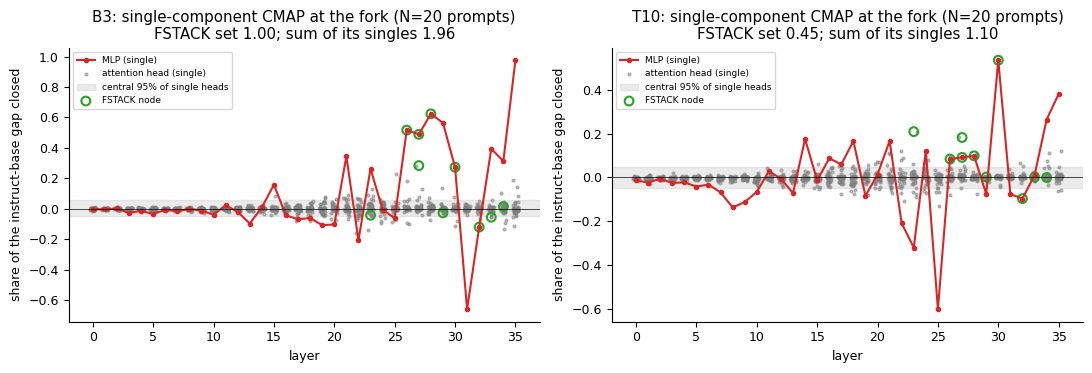

14:51:41|INFO   |figure F3_b2_singles_by_layer


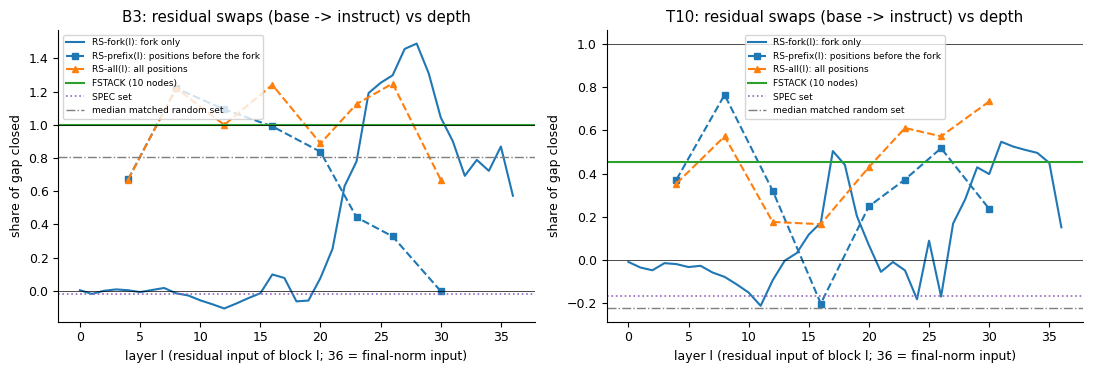

14:51:42|INFO   |figure F4_b2_residual_swaps


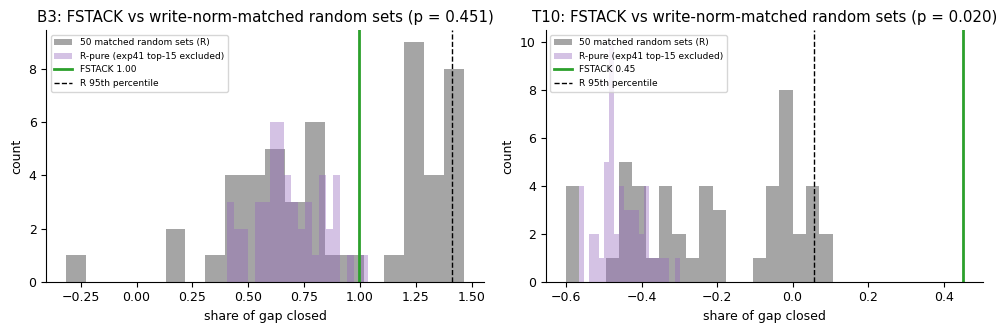

14:51:42|INFO   |figure F5_b2_random_null


In [16]:
setup_logging("figures9")
b2 = read_json(RESULTS_DIR / "b2_summary.json")   # as figures9.main(): the summary file written by the analysis
f3_singles(b2)
f4_rs(b2)
f5_null(b2)

## 8. Activation geometry at the fork (F8-style)

F8 looks at the actual activation space: the block-30 output (the residual entering block 31) at the fork, a
4096-d vector per prompt and state. The demo data holds these vectors as exact bf16 values for four states per prompt:

* the unpatched instruct model;
* the instruct model with FSTACK patched;
* the instruct model with the median matched random set patched;
* the instruct model with RS-fork(23) patched.

Every point is coloured by the fork margin m its state produced, from blue (Prim / DFS more likely) to red (default
class more likely).

**One deviation from the original F8.** The original also plotted the **base model's** own block-30 state and fit the
PCA on the instruct + base states. Those base states lived only in the ~12 GB activation cache (`cache/base_<unit>.pt`),
which the original run did not keep. Here the PCA is therefore fit on all four plotted states. The markers, colours and
projection are otherwise the original code. The median random set is the one of the full 20-prompt run
(`metadata.geometry.median_R_index`), the same set the original F8 used.

/tmp/ipykernel_841/2451970436.py:43: UserWarning: You passed a edgecolor/edgecolors ('k') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  sc = ax.scatter(Y[ii, 0], Y[ii, 1], c=[cols[i] for i in ii], cmap="coolwarm", marker=mk, s=28,


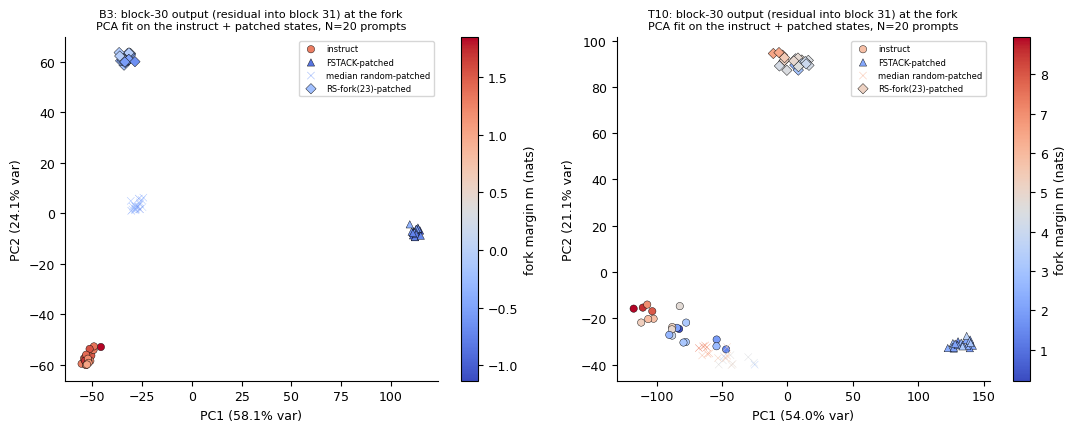

14:51:43|INFO   |figure F8_b2_geometry_pca_demo


B3: mean |instruct state| = 643
   FSTACK-patched           moves the state by  173.0 (L2), cosine with the FSTACK shift +1.00
   median random-patched    moves the state by  102.2 (L2), cosine with the FSTACK shift +0.48
   RS-fork(23)-patched      moves the state by  120.7 (L2), cosine with the FSTACK shift +0.43
T10: mean |instruct state| = 574
   FSTACK-patched           moves the state by  230.1 (L2), cosine with the FSTACK shift +1.00
   median random-patched    moves the state by  129.5 (L2), cosine with the FSTACK shift +0.48
   RS-fork(23)-patched      moves the state by  163.8 (L2), cosine with the FSTACK shift +0.62


In [17]:
def bf16_from_b64(s: str) -> np.ndarray:
    """notebook only: exact bf16 -> float32 decode of a stored 4096-d fork state."""
    return (np.frombuffer(base64.b64decode(s), "<i2").astype(np.int32) << 16).view(np.float32)


def f8_geometry(b2: dict) -> dict:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
    disp = {}
    for ax, (u, r) in zip(axes, b2["units"].items()):
        tf = read_jsonl(RESULTS_DIR / f"b2_tf_{u}.jsonl")
        pids = []
        m = {}
        for row in tf:
            if row["pid"] not in pids:
                pids.append(row["pid"])
            m[(row["pid"], row["arm"])] = row["m"]
        med = M["geometry"]["median_R_index"][u]      # original: int(np.argsort(r["null_R"]["shares"])[25])
        G = {e["pid"]: e["geom_bf16_b64"] for e in data["examples"] if e["unit"] == u}   # original: cache/geom_*.pt
        pts, cols, kinds = [], [], []
        for pi, p in enumerate(pids):
            g = G.get(p)
            if g is None:
                continue
            # original also had ("base", cache/base_<u>.pt resid[31], m_B): not kept by the run, so omitted here
            for kind, vec, mm in (("instruct", g["none"], m[(p, "none")]),
                                  ("FSTACK-patched", g["FSTACK"], m[(p, "FSTACK")]),
                                  ("median random-patched", g[f"R{med}"], m[(p, f"R{med}")]),
                                  ("RS-fork(23)-patched", g["RSfork23"], m[(p, "RSfork23")])):
                pts.append(bf16_from_b64(vec))
                cols.append(mm)
                kinds.append(kind)
        X = np.stack(pts)
        fit = X                                       # original: X[instruct + base rows]
        mu = fit.mean(0)
        U_, Sv, Vt = np.linalg.svd(fit - mu, full_matrices=False)
        ev = Sv ** 2 / (Sv ** 2).sum()
        Y = (X - mu) @ Vt[:2].T
        marks = {"instruct": "o", "FSTACK-patched": "^", "median random-patched": "x",
                 "RS-fork(23)-patched": "D"}
        sc = None
        for kind, mk in marks.items():
            ii = [i for i, k in enumerate(kinds) if k == kind]
            sc = ax.scatter(Y[ii, 0], Y[ii, 1], c=[cols[i] for i in ii], cmap="coolwarm", marker=mk, s=28,
                            vmin=min(cols), vmax=max(cols), label=kind, edgecolors="k", linewidths=0.3)
        fig.colorbar(sc, ax=ax, label="fork margin m (nats)")
        ax.set_xlabel(f"PC1 ({ev[0] * 100:.1f}% var)")
        ax.set_ylabel(f"PC2 ({ev[1] * 100:.1f}% var)")
        ax.set_title(f"{u}: block-30 output (residual into block 31) at the fork\nPCA fit on the instruct + patched "
                     f"states, N={len(pids)} prompts", fontsize=8)
        ax.legend(fontsize=6, loc="best")
        # notebook only: how far, and in which direction, each patch moves the state (per prompt, from instruct)
        ki = {k: [i for i, kk in enumerate(kinds) if kk == k] for k in marks}
        d_f = X[ki["FSTACK-patched"]] - X[ki["instruct"]]
        cosf = lambda a, b: float(np.mean(np.sum(a * b, 1) / (np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1))))  # noqa: E731
        disp[u] = {k: {"mean_norm": float(np.linalg.norm(X[ki[k]] - X[ki["instruct"]], axis=1).mean()),
                       "mean_cos_with_FSTACK_shift": cosf(X[ki[k]] - X[ki["instruct"]], d_f)}
                   for k in ("FSTACK-patched", "median random-patched", "RS-fork(23)-patched")}
        disp[u]["instruct_state_norm"] = float(np.linalg.norm(X[ki["instruct"]], axis=1).mean())
    save(fig, "F8_b2_geometry_pca_demo")
    return disp


disp = f8_geometry(b2)
for u, d in disp.items():
    print(f"{u}: mean |instruct state| = {d['instruct_state_norm']:.0f}")
    for k in ("FSTACK-patched", "median random-patched", "RS-fork(23)-patched"):
        print(f"   {k:<24} moves the state by {d[k]['mean_norm']:6.1f} (L2), cosine with the FSTACK shift "
              f"{d[k]['mean_cos_with_FSTACK_shift']:+.2f}")

## 9. Independent re-derivation (`src/rederive9.py`, B2 part)

The original pipeline re-derives every headline number from the raw per-prompt rows with the **Python standard library
only** (no numpy, no project imports). It compares them with the summary file the analysis wrote (tolerance 1e-6) and
adds placebos that **must fail**:

* **node-label permutation**: treat a random R set as "the circuit" and test it against the other random sets. It
  should be significant (p ≤ 0.05) in at most about 10 % of draws.
* **anchor swap**: recompute the FSTACK share with the instruct and base anchors swapped. It must not reproduce the
  real share; it comes out as 1 − share.

The function is renamed `rederive_b2` because the notebook already has analysis9's `b2`. As above, the hard-coded 50
random sets and 200 placebo draws read `N_RAND` / `N_PLACEBO_DRAWS`.

In [18]:
RES = RESULTS_DIR
TOL = 1e-6


def jl(p: Path) -> list[dict]:
    with open(p) as fh:
        return [json.loads(x) for x in fh if x.strip()]


def pct(xs: list[float], q: float) -> float:
    """numpy-default (linear) percentile."""
    s = sorted(xs)
    k = (len(s) - 1) * q / 100
    f = int(k)
    c = min(f + 1, len(s) - 1)
    return s[f] + (s[c] - s[f]) * (k - f)


def rederive_b2(mism: list, out: dict) -> None:
    summ = json.loads((RES / "b2_summary.json").read_text())
    for u in ("B3", "T10"):
        rows = jl(RES / f"b2_tf_{u}.jsonl")
        mI, mB, arm = {}, {}, {}
        for r in rows:
            mI[r["pid"]] = r["m_I"]
            mB[r["pid"]] = r["m_B"]
            arm.setdefault(r["arm"], {})[r["pid"]] = r["m"]
        pids = sorted(mI)
        den = sum(mI[p] - mB[p] for p in pids)

        def sh(a: str) -> float:
            return sum(mI[p] - arm[a][p] for p in pids) / den
        rec = {"FSTACK": sh("FSTACK"), "RSfork36": sh("RSfork36"), "RSfork23": sh("RSfork23"),
               "SPEC": sh("SPEC") if "SPEC" in arm else None, "gap_mean": statistics.mean(mI[p] - mB[p] for p in pids)}
        R = [sh(f"R{s}") for s in range(N_RAND)]                                     # original: range(50)
        rec["R_median"] = statistics.median(R)
        rec["R_p95"] = pct(R, 95)
        rec["R_empirical_p"] = (1 + sum(x >= rec["FSTACK"] for x in R)) / (N_RAND + 1)  # original: / 51
        S = summ["units"][u]
        cmp_ = {"FSTACK": S["arms"]["FSTACK"]["share"], "RSfork36": S["RS_fork"]["36"],
                "RSfork23": S["RS_fork"]["23"], "SPEC": S["arms"].get("SPEC", {}).get("share"),
                "gap_mean": S["gap_mean"], "R_median": S["null_R"]["median"], "R_p95": S["null_R"]["p95"],
                "R_empirical_p": S["null_R"]["empirical_p_upper"]}
        for k, v in rec.items():
            if v is None or cmp_.get(k) is None:
                continue
            if abs(v - cmp_[k]) > TOL:
                mism.append(f"B2 {u} {k}: rederived {v} vs summary {cmp_[k]}")
        # placebo: node-label permutation -> treat a random R set as 'the circuit' against the other 49 sets
        rng = random.Random(7)
        ps = []
        for _ in range(N_PLACEBO_DRAWS):                                              # original: range(200)
            j = rng.randrange(N_RAND)                                                 # original: randrange(50)
            others = [x for i, x in enumerate(R) if i != j]
            ps.append((1 + sum(x >= R[j] for x in others)) / N_RAND)                  # original: / 50
        rec["placebo_permuted_node_labels_frac_p_le_0.05"] = sum(p <= 0.05 for p in ps) / len(ps)
        rec["placebo_permuted_node_labels_fails"] = rec["placebo_permuted_node_labels_frac_p_le_0.05"] <= 0.10
        # placebo: swap the instruct and base anchors -> FSTACK 'share' sign flips relative to the gap
        rec["placebo_anchor_swap_share"] = sum(mB[p] - arm["FSTACK"][p] for p in pids) / sum(mB[p] - mI[p]
                                                                                             for p in pids)
        out[f"B2_{u}"] = rec

Run the re-derivation against `results/b2_summary.json` and write `results/rederive.json`. The original run reported
0 mismatches; the placebo rows must report `fails as required: True`.

In [19]:
mism: list[str] = []
out_rd: dict = {}
rederive_b2(mism, out_rd)
out_rd["mismatches"] = mism
out_rd["n_mismatches"] = len(mism)
(RES / "rederive.json").write_text(json.dumps(out_rd, indent=1))
print(f"rederive: {len(mism)} mismatches")
for m_ in mism[:20]:
    print("  ", m_)
for u in ("B3", "T10"):
    r = out_rd[f"B2_{u}"]
    print(f"{u}: stdlib FSTACK share {r['FSTACK']:.6f}, R median {r['R_median']:.6f}, empirical p {r['R_empirical_p']:.4f}"
          f" | placebo (permuted node labels) frac p<=0.05 = {r['placebo_permuted_node_labels_frac_p_le_0.05']:.3f}"
          f" -> fails as required: {r['placebo_permuted_node_labels_fails']}; anchor-swap share "
          f"{r['placebo_anchor_swap_share']:+.3f}")

rederive: 0 mismatches
B3: stdlib FSTACK share 0.997696, R median 0.807268, empirical p 0.4510 | placebo (permuted node labels) frac p<=0.05 = 0.030 -> fails as required: True; anchor-swap share +0.002
T10: stdlib FSTACK share 0.451707, R median -0.223247, empirical p 0.0196 | placebo (permuted node labels) frac p<=0.05 = 0.055 -> fails as required: True; anchor-swap share +0.548


## 10. Results

The table puts the numbers recomputed in this notebook next to the original run's values (stored in
`metadata.reference_original_run`). With the original configuration (20 prompts, `N_BOOT = 10000`, 50 random sets)
they agree exactly, bootstrap CIs included. With a reduced configuration the demo column covers fewer prompts and sets.
The figure below shows the per-prompt raw data and the shares that decide the verdict.

In [20]:
b2s = read_json(RESULTS_DIR / "b2_summary.json")
REF = M["reference_original_run"]


def _f(v):
    if isinstance(v, bool) or v is None or isinstance(v, str):
        return str(v)
    if isinstance(v, (list, tuple)):
        return "[" + ", ".join(f"{x:.2f}" for x in v) + "]"
    if isinstance(v, int):
        return str(v)
    return f"{v:.3f}"


lines = []
for u in UNITS:
    r, ref = b2s["units"][u], REF[u]
    lines += [(u, "prompts", r["n_prompts"], ref["n_prompts"]),
              (u, "gap m_I - m_B (nats)", r["gap_mean"], ref["gap_mean"]),
              (u, "FSTACK share", r["arms"]["FSTACK"]["share"], ref["FSTACK_share"]),
              (u, "FSTACK share 95% CI", r["arms"]["FSTACK"]["share_ci95"], ref["FSTACK_share_ci95"]),
              (u, "F_MLP share", r["arms"]["F_MLP"]["share"], ref["F_MLP_share"]),
              (u, "F_HEAD share", r["arms"]["F_HEAD"]["share"], ref["F_HEAD_share"]),
              (u, "random sets R: median share", r["null_R"]["median"], ref["null_R"]["median"]),
              (u, "random sets R: 95th pct", r["null_R"]["p95"], ref["null_R"]["p95"]),
              (u, "empirical p (FSTACK vs R)", r["null_R"]["empirical_p_upper"], ref["null_R"]["empirical_p_upper"]),
              (u, "R-pure: median / p", [r["null_Rpure"]["median"], r["null_Rpure"]["empirical_p_upper"]],
               [ref["null_Rpure"]["median"], ref["null_Rpure"]["empirical_p_upper"]]),
              (u, "SPEC share", r["arms"]["SPEC"]["share"], ref["SPEC_share"]),
              (u, "RS-fork(23) / RS-fork(36)", [r["RS_fork"]["23"], r["RS_fork"]["36"]],
               [ref["RS_fork_23"], ref["RS_fork_36"]]),
              (u, "RS-prefix(23)", r["RS_prefix"]["23"], ref["RS_prefix_23"]),
              (u, "unembedding-only share (carried)", r["readout_decomposition_cpu"]["share_unembedding_only"],
               M["carried"][u]["readout_decomposition_cpu"]["share_unembedding_only"]),
              (u, "REV: share opened by FSTACK", r["REV"]["share_opened_FSTACK"], ref["REV"]["share_opened_FSTACK"]),
              (u, "Q1 / Q2 / Q3", f"{r['Q1']} / {r['Q2']} / {r['Q3']}", f"{ref['Q1']} / {ref['Q2']} / {ref['Q3']}"),
              (u, "localisation", r["localisation"], ref["localisation"])]
lines.append(("both", "B2 verdict", b2s["verdict"], REF["verdict"]))
print(f"{'unit':<5} {'quantity':<34} {'this notebook':>22} {'original run':>22}")
print("-" * 86)
for u, k, a, b in lines:
    print(f"{u:<5} {k:<34} {_f(a):>22} {_f(b):>22}")

unit  quantity                                    this notebook           original run
--------------------------------------------------------------------------------------
B3    prompts                                                20                     20
B3    gap m_I - m_B (nats)                                2.059                  2.059
B3    FSTACK share                                        0.998                  0.998
B3    FSTACK share 95% CI                          [0.96, 1.04]           [0.96, 1.04]
B3    F_MLP share                                         1.079                  1.079
B3    F_HEAD share                                        0.174                  0.174
B3    random sets R: median share                         0.807                  0.807
B3    random sets R: 95th pct                             1.413                  1.413
B3    empirical p (FSTACK vs R)                           0.451                  0.451
B3    R-pure: median / p                   

**Summary figure.**

* **Left**: the raw per-prompt fork margins, which are the data every share is computed from: the two anchors (instruct
  `m_I`, base `m_B`) and three patched instruct runs. Above 0 the default algorithm class is more likely, below 0 the
  alternative.
* **Right**: the shares that enter the committed rules, with their 95 % bootstrap CIs. The grey band is the central
  90 % of the matched random sets.

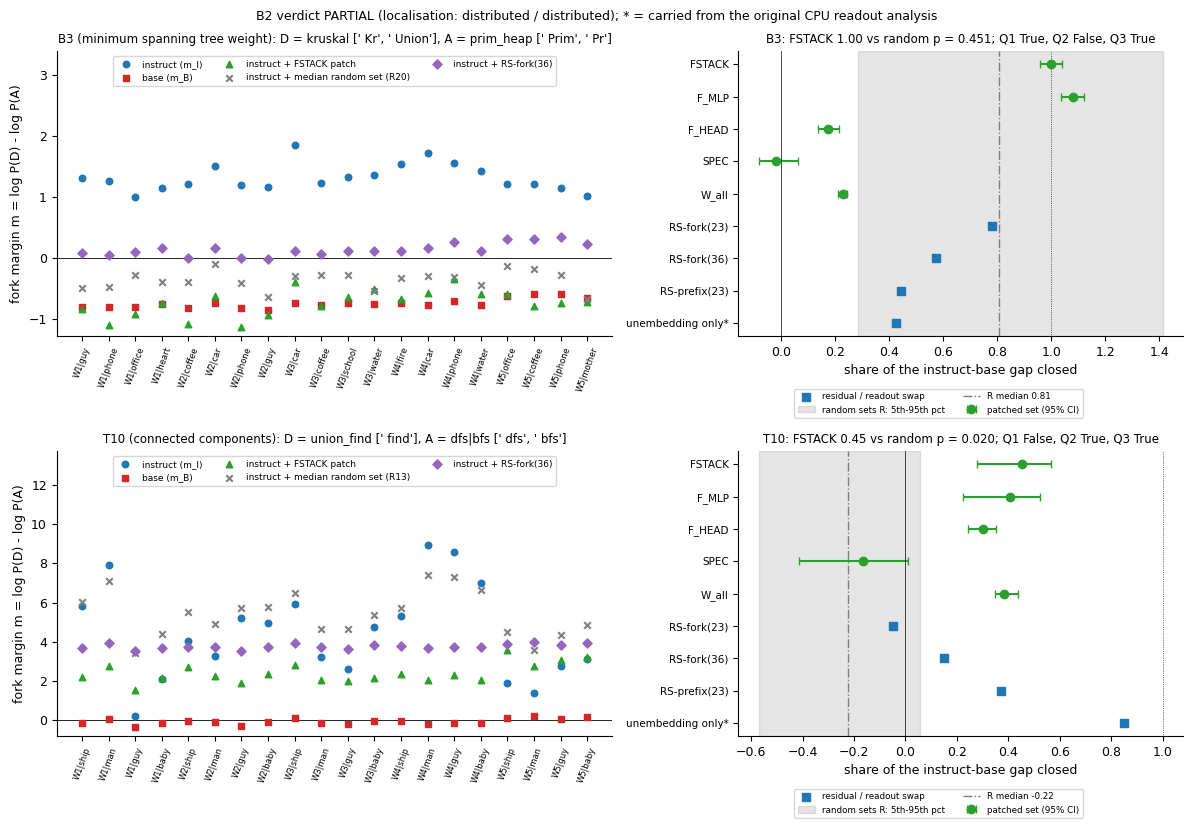

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8.4), gridspec_kw={"width_ratios": [1.25, 1]})
for row, u in enumerate(UNITS):
    r = b2s["units"][u]
    pids, by, mI, mB = rows_by_arm(u)
    med = int(np.argsort(r["null_R"]["shares"])[len(r["null_R"]["shares"]) // 2])
    # (left) per-prompt fork margins: anchors and three patched arms
    ax = axes[row, 0]
    x = np.arange(len(pids))
    for lab, vals, mk, c in (("instruct (m_I)", [mI[p] for p in pids], "o", C_I),
                             ("base (m_B)", [mB[p] for p in pids], "s", C_B),
                             ("instruct + FSTACK patch", [by["FSTACK"][p] for p in pids], "^", C_F),
                             (f"instruct + median random set (R{med})", [by[f"R{med}"][p] for p in pids], "x", C_R),
                             ("instruct + RS-fork(36)", [by["RSfork36"][p] for p in pids], "D", C_S)):
        ax.scatter(x, vals, marker=mk, color=c, s=22, label=lab, zorder=3)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels(pids, rotation=70, fontsize=6)
    ax.set_ylabel("fork margin m = log P(D) - log P(A)")
    U = UNITS_DATA[u]
    ax.set_title(f"{u} ({U['name']}): D = {U['D_class']} {U['D_tokens'][:2]}, A = {U['A_class']} {U['A_tokens'][:2]}",
                 fontsize=8.5)
    y0, y1 = ax.get_ylim()
    ax.set_ylim(y0, y1 + 0.42 * (y1 - y0))          # head room for the legend
    ax.legend(fontsize=6.5, ncol=3, loc="upper center")
    # (right) the shares that decide the verdict, with bootstrap CIs, against the random null
    ax = axes[row, 1]
    names = ["FSTACK", "F_MLP", "F_HEAD", "SPEC", "W_all"]
    vals = [r["arms"][n]["share"] for n in names]
    lo = [r["arms"][n]["share"] - r["arms"][n]["share_ci95"][0] for n in names]
    hi = [r["arms"][n]["share_ci95"][1] - r["arms"][n]["share"] for n in names]
    extra = [("RS-fork(23)", r["RS_fork"]["23"]), ("RS-fork(36)", r["RS_fork"]["36"]),
             ("RS-prefix(23)", r["RS_prefix"]["23"]),
             ("unembedding only*", r["readout_decomposition_cpu"]["share_unembedding_only"])]
    yy = np.arange(len(names) + len(extra))[::-1]
    ax.errorbar(vals, yy[:len(names)], xerr=[lo, hi], fmt="o", color=C_F, capsize=3, label="patched set (95% CI)")
    ax.scatter([v for _, v in extra], yy[len(names):], marker="s", color=C_I, zorder=3, label="residual / readout swap")
    nr = r["null_R"]
    ax.axvspan(np.percentile(nr["shares"], 5), nr["p95"], color=C_R, alpha=0.2, label="random sets R: 5th-95th pct")
    ax.axvline(nr["median"], color=C_R, ls="-.", lw=1, label=f"R median {nr['median']:.2f}")
    ax.axvline(0, color="k", lw=0.5)
    ax.axvline(1, color="k", lw=0.5, ls=":")
    ax.set_yticks(yy)
    ax.set_yticklabels(names + [n for n, _ in extra], fontsize=7.5)
    ax.set_xlabel("share of the instruct-base gap closed")
    ax.set_title(f"{u}: FSTACK {r['arms']['FSTACK']['share']:.2f} vs random p = {nr['empirical_p_upper']:.3f}; "
                 f"Q1 {r['Q1']}, Q2 {r['Q2']}, Q3 {r['Q3']}", fontsize=8.5)
    ax.legend(fontsize=6.3, loc="upper center", bbox_to_anchor=(0.45, -0.17), ncol=2)
fig.suptitle(f"B2 verdict {b2s['verdict']} (localisation: {b2s['units']['B3']['localisation']} / "
             f"{b2s['units']['T10']['localisation']}); * = carried from the original CPU readout analysis", fontsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "summary_b2.png", dpi=150)
plt.show()

### What the numbers say (original configuration: 20 prompts per unit)

* **The tuned model is decided where its base is not.** At the MST fork the base model leans to Prim
  (`m_B` from −0.85 to −0.6) and the instruct model to Kruskal (`m_I` from 1.0 to 1.85). At the connected-components
  fork the base model is indifferent (`m_B` ≈ 0) and the instruct model prefers `find` by 0.2 to 9 nats.
* **Not written upstream at the task statement.** The task-specification nodes close nothing (SPEC ≈ 0). By layer 23
  the earlier positions carry less than half of the gap: swapping the residual stream at all positions before the
  fork closes 0.44 / 0.37, below the committed 0.5 "written upstream" threshold. Swaps at earlier layers close more
  (up to 1.2 on MST at layer 8), because they hand the instruct model a base-model reading of the whole prompt. At the
  fork position itself, RS-fork(l) is near 0 through layer 15 and largest in the late layers (F4): on MST it peaks at
  1.49 at layer 28; on CC it reaches 0.5-0.55 at layers 17-18 and 31-34.
* **MST (B3): many late MLPs carry it redundantly.**
  * FSTACK closes the whole gap (1.00 [0.96, 1.04]), but the median write-norm-matched random late set closes 0.81
    (p = 0.45).
  * Single late MLPs close a lot on their own (L35 0.98, L28 0.62, L29 0.56, L26 0.52), and FSTACK's joint share is
    half the sum of its singles (1.00 vs 1.96).
  * Base values taken from a *different* prompt work as well as the matched ones (`xprompt_FSTACK` 1.00).
  * So what FSTACK transplants is a generic, prompt-independent base-vs-tuned offset of the late MLPs rather than a
    specific circuit. Q2 fails.
* **Connected components (T10): specific but partial.** FSTACK closes 0.45 [0.28, 0.57] against a random median of
  −0.22 (p = 0.020). Most of the CC gap is not in the residual stream at all: reading the base model's own final
  residual with the **tuned unembedding** reproduces 85 % of it. This is why RS-fork(36), which swaps the entire final
  residual, closes only 0.15.
* **Activation space (Section 8).**
  * FSTACK moves the block-30 state the furthest (≈ 175 / 230 L2 against a state norm of ≈ 600).
  * The median random set moves it about 60 % as far and only partly in the same direction (cosine ≈ 0.5), and
    RS-fork(23) moves it elsewhere again.
  * On MST all three still push the margin to the Prim side (blue points): quite different late perturbations reach
    the same decision, which is the geometric face of the non-specificity found by the null test. On CC the
    random-patched states keep a high margin (red ×).
* **Committed verdict: PARTIAL.** Q1 fails on CC, Q2 fails on MST, Q3 holds; localisation is "distributed".

For the run's question about the *mean answer*: tuning does not add a dedicated "choose Kruskal" step upstream, at the
task statement. At a fork where the base model leans the other way (MST: Prim) or is undecided (CC), tuning installs
a confident default late in the network, partly as a redundant late-MLP offset and partly in the unembedding itself.
The minority algorithm is still there to be found. In the original run's generation test, a one-token patch at the fork flipped 19/30 MST
programs to Prim, but a matched random late patch did the same (19/30). On CC only replacing the whole fork
distribution with the base model's brought DFS back (18/30).

**Running the full pipeline** (needs a 24 GB GPU, `HF_TOKEN` with access to Gemma 3 and Llama 3.1, about 65 GB of
weights and about 1 GPU-hour), from the artifact folder of the repository:

```bash
uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r pyproject.toml
.venv/bin/python src/download_models.py
.venv/bin/python method.py --stages all
```